Use polynomial and RBF kernels in SVM by manually deriving and applying kernel transformations, implementing the kernel trick without built-in functions, and comparing performance based on support vector distributions.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)
print("Target classes:", np.unique(y))

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Target classes: [0 1]


In [7]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_indices = indices[:split]
test_indices = indices[split:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = np.where(y[train_indices] == 1, 1, -1)
y_test = np.where(y[test_indices] == 1, 1, -1)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [8]:
def polynomial_kernel(X1, X2, degree=3, gamma=1.0, coef0=1.0):
    return (gamma * (X1 @ X2.T) + coef0) ** degree


def rbf_kernel(X1, X2, gamma=0.1):
    distances = (
        np.sum(X1 ** 2, axis=1).reshape(-1, 1)
        + np.sum(X2 ** 2, axis=1)
        - 2 * (X1 @ X2.T)
    )

    distances = np.maximum(distances, 0)
    return np.exp(-gamma * distances)


print("Polynomial and RBF kernel functions created.")

Polynomial and RBF kernel functions created.


In [9]:
def train_kernel_svm(K, y, C=1.0, tolerance=0.001,
                     max_passes=5, max_iter=10000):
    n = len(y)
    alpha = np.zeros(n)
    bias = 0.0
    passes = 0
    iterations = 0

    while passes < max_passes and iterations < max_iter:
        changed = 0

        for i in range(n):
            if iterations >= max_iter:
                break

            errors = K @ (alpha * y) + bias - y
            Ei = errors[i]

            if ((y[i] * Ei < -tolerance and alpha[i] < C) or
                (y[i] * Ei > tolerance and alpha[i] > 0)):

                candidates = np.delete(np.arange(n), i)
                j = np.random.choice(candidates)
                Ej = errors[j]

                old_ai = alpha[i]
                old_aj = alpha[j]

                if y[i] != y[j]:
                    L = max(0, old_aj - old_ai)
                    H = min(C, C + old_aj - old_ai)
                else:
                    L = max(0, old_ai + old_aj - C)
                    H = min(C, old_ai + old_aj)

                if L == H:
                    iterations += 1
                    continue

                eta = 2 * K[i, j] - K[i, i] - K[j, j]

                if eta >= 0:
                    iterations += 1
                    continue

                alpha[j] -= y[j] * (Ei - Ej) / eta
                alpha[j] = np.clip(alpha[j], L, H)

                if abs(alpha[j] - old_aj) < 1e-5:
                    alpha[j] = old_aj
                    iterations += 1
                    continue

                alpha[i] += y[i] * y[j] * (old_aj - alpha[j])

                b1 = (
                    bias - Ei
                    - y[i] * (alpha[i] - old_ai) * K[i, i]
                    - y[j] * (alpha[j] - old_aj) * K[i, j]
                )

                b2 = (
                    bias - Ej
                    - y[i] * (alpha[i] - old_ai) * K[i, j]
                    - y[j] * (alpha[j] - old_aj) * K[j, j]
                )

                if 0 < alpha[i] < C:
                    bias = b1
                elif 0 < alpha[j] < C:
                    bias = b2
                else:
                    bias = (b1 + b2) / 2

                changed += 1

            iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    return alpha, bias

In [10]:
np.random.seed(42)

K_poly = polynomial_kernel(
    X_train, X_train, degree=3, gamma=0.2, coef0=1
)

alpha_poly, bias_poly = train_kernel_svm(
    K_poly, y_train, C=1.0
)

K_rbf = rbf_kernel(X_train, X_train, gamma=0.1)

alpha_rbf, bias_rbf = train_kernel_svm(
    K_rbf, y_train, C=1.0
)

print("Polynomial SVM training completed.")
print("RBF SVM training completed.")

Polynomial SVM training completed.
RBF SVM training completed.


In [11]:
def predict_kernel_svm(X_train, y_train, alpha, bias, X_test, kernel):
    support = alpha > 1e-5

    K_test = kernel(X_test, X_train[support])

    scores = K_test @ (alpha[support] * y_train[support]) + bias

    return np.where(scores >= 0, 1, -1)


poly_predictions = predict_kernel_svm(
    X_train, y_train, alpha_poly, bias_poly,
    X_test,
    lambda A, B: polynomial_kernel(A, B, degree=3, gamma=0.2, coef0=1)
)

rbf_predictions = predict_kernel_svm(
    X_train, y_train, alpha_rbf, bias_rbf,
    X_test,
    lambda A, B: rbf_kernel(A, B, gamma=0.1)
)

poly_accuracy = np.mean(poly_predictions == y_test) * 100
rbf_accuracy = np.mean(rbf_predictions == y_test) * 100

print("Polynomial SVM Accuracy:", round(poly_accuracy, 2), "%")
print("RBF SVM Accuracy:", round(rbf_accuracy, 2), "%")

Polynomial SVM Accuracy: 87.5 %
RBF SVM Accuracy: 81.25 %


In [12]:
poly_support = alpha_poly > 1e-5
rbf_support = alpha_rbf > 1e-5

poly_count = np.sum(poly_support)
rbf_count = np.sum(rbf_support)

poly_positive = np.sum(poly_support & (y_train == 1))
poly_negative = np.sum(poly_support & (y_train == -1))

rbf_positive = np.sum(rbf_support & (y_train == 1))
rbf_negative = np.sum(rbf_support & (y_train == -1))

print("Polynomial Kernel Support Vectors:", poly_count)
print("  Positive class:", poly_positive)
print("  Negative class:", poly_negative)

print("\nRBF Kernel Support Vectors:", rbf_count)
print("  Positive class:", rbf_positive)
print("  Negative class:", rbf_negative)

Polynomial Kernel Support Vectors: 31
  Positive class: 19
  Negative class: 12

RBF Kernel Support Vectors: 36
  Positive class: 21
  Negative class: 15


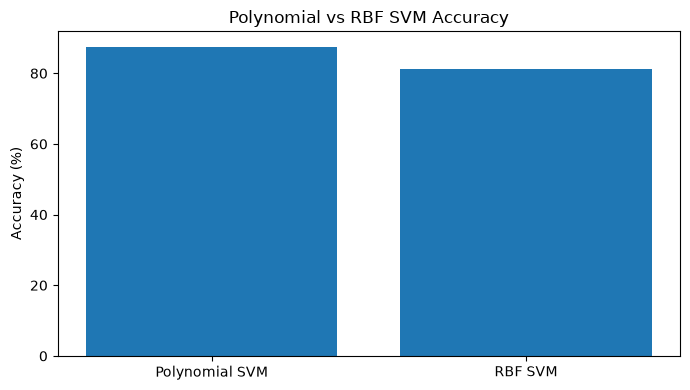

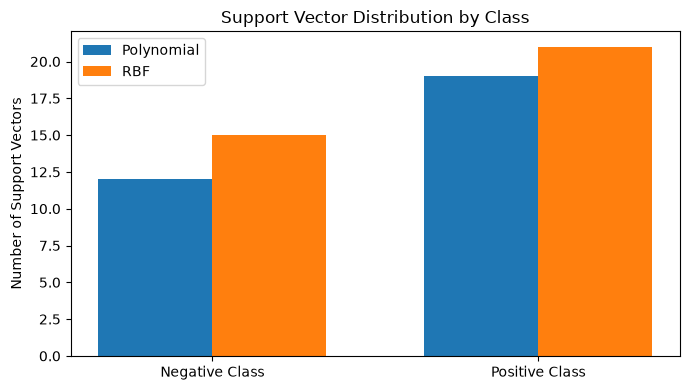

In [13]:
models = ["Polynomial SVM", "RBF SVM"]
accuracies = [poly_accuracy, rbf_accuracy]

plt.figure(figsize=(7, 4))
plt.bar(models, accuracies)
plt.ylabel("Accuracy (%)")
plt.title("Polynomial vs RBF SVM Accuracy")
plt.tight_layout()
plt.show()

x = np.arange(2)
width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(
    x - width / 2,
    [poly_negative, poly_positive],
    width,
    label="Polynomial"
)
plt.bar(
    x + width / 2,
    [rbf_negative, rbf_positive],
    width,
    label="RBF"
)

plt.xticks(x, ["Negative Class", "Positive Class"])
plt.ylabel("Number of Support Vectors")
plt.title("Support Vector Distribution by Class")
plt.legend()
plt.tight_layout()
plt.show()